# LIFESTYLE DATA EXAMPLE

Classification example: RandomUnderSampler

# Undersampling with RandomUnderSampler

With RandomUnderSampler, no need to process the dataset into all numeric format (categories etc.).

In [23]:
# pip install imblearn
import pandas as pd
import numpy as np
import seaborn as sns
from imblearn.under_sampling import RandomUnderSampler

# load the data
df = pd.read_csv("../../lifestyle_sustainability_data.csv")
df.head(3)

,ParticipantID,Age,Location,DietType,LocalFoodFrequency,TransportationMode,EnergySource,HomeType,HomeSize,ClothingFrequency,SustainableBrands,EnvironmentalAwareness,CommunityInvolvement,MonthlyElectricityConsumption,MonthlyWaterConsumption,Gender,UsingPlasticProducts,DisposalMethods,PhysicalActivities,Rating
0,1,35,Urban,Mostly Plant-Based,Often,Bike,Renewable,Apartment,800,Rarely,True,5,High,100,1500,Female,Rarely,Composting,High,5
1,2,28,Suburban,Balanced,Sometimes,Public Transit,Mixed,House,1500,Sometimes,True,4,Moderate,250,3000,Male,Sometimes,Recycling,Moderate,4
2,3,65,Rural,Mostly Animal-Based,Rarely,Car,Non-Renewable,House,2500,Often,False,2,Low,400,4500,Male,Often,Landfill,Low,1


In [24]:
# We're not allowed to have NaN values in the dataset once we use undersampling here.
df = df.dropna()

<Axes: xlabel='Rating', ylabel='Count'>

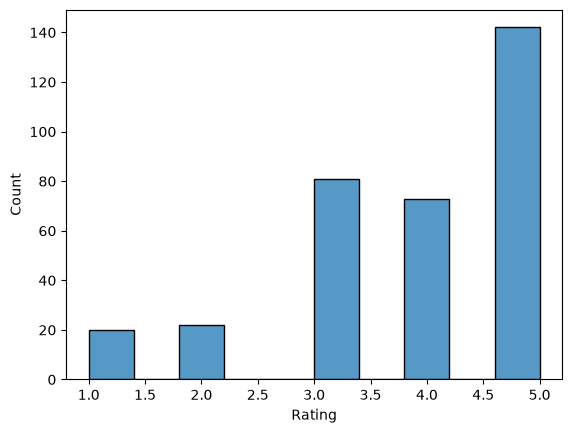

In [25]:
# let's see our current target distribution
# df["Rating"].value_counts()

sns.histplot(df, x="Rating")

## Perform RandomUnderSampling

In [26]:
from imblearn.under_sampling import RandomUnderSampler

# Split the dataset. If we don't do this, we WILL have a data leakage when training
# the model.
X = df.drop(columns="Rating", axis=1)
y = df["Rating"]

# We set a stable seed for the sampler.
sampler = RandomUnderSampler(random_state=321)

# We use the sampler, and output two variables (X, y respectively).
X_resampled, y_resampled = sampler.fit_resample(X, y)

# Let's make an independent dataframe to be safe.
df_resampled = X_resampled.copy()

# And let's add the `Pop` column back into it.
df_resampled["Rating"] = y_resampled

<Axes: xlabel='Rating', ylabel='Count'>

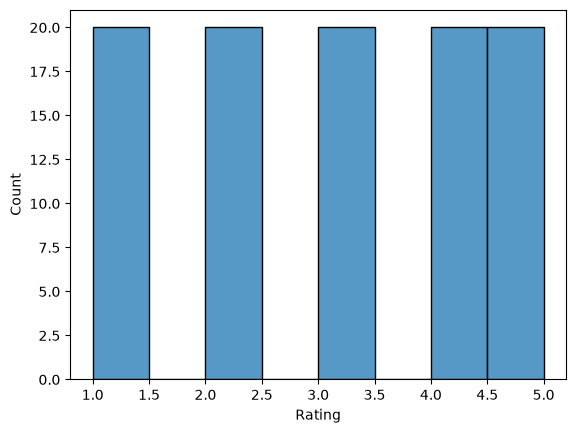

In [27]:
# we now have approximately 100 rows of data (80% lost)
sns.histplot(df_resampled, x="Rating")

In [28]:
df_resampled

,ParticipantID,Age,Location,DietType,LocalFoodFrequency,TransportationMode,EnergySource,HomeType,HomeSize,ClothingFrequency,SustainableBrands,EnvironmentalAwareness,CommunityInvolvement,MonthlyElectricityConsumption,MonthlyWaterConsumption,Gender,UsingPlasticProducts,DisposalMethods,PhysicalActivities,Rating
2,3,65,Rural,Mostly Animal-Based,Rarely,Car,Non-Renewable,House,2500,Often,False,2,Low,400,4500,Male,Often,Landfill,Low,1
76,77,24,Urban,Mostly Animal-Based,Rarely,Car,Non-Renewable,Apartment,1110,Always,False,2,Low,375,4250,Male,Often,Landfill,Low,1
93,94,33,Urban,Mostly Animal-Based,Rarely,Car,Non-Renewable,House,2180,Often,False,2,Low,425,4750,Male,Often,Landfill,Low,1
202,203,65,Rural,Mostly Animal-Based,Rarely,Car,Non-Renewable,House,2500,Often,False,2,Low,400,4500,Male,Often,Landfill,Low,1
245,246,56,Suburban,Mostly Animal-Based,Sometimes,Walk,Non-Renewable,Apartment,1594,Sometimes,False,2,High,469,4546,Non-Binary,Often,Recycling,Low,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
210,211,48,Suburban,Mostly Plant-Based,Often,Bike,Renewable,House,1400,Sometimes,True,5,High,120,1800,Male,Rarely,Composting,High,5
97,98,23,Urban,Mostly Plant-Based,Always,Walk,Renewable,House,1270,Rarely,True,5,High,105,1500,Female,Never,Composting,High,5
328,329,60,Urban,Mostly Plant-Based,Sometimes,Bike,Renewable,House,2941,Rarely,True,4,Moderate,111,3697,Non-Binary,Often,Recycling,Moderate,5
481,482,52,Rural,Mostly Plant-Based,Always,Public Transit,Mixed,House,1567,Rarely,True,5,High,280,3200,Non-Binary,Sometimes,Recycling,Moderate,5


## Let's compare the statistics before and after

First, basic statistics with describe()!

In [29]:
df.describe()

,ParticipantID,Age,HomeSize,EnvironmentalAwareness,MonthlyElectricityConsumption,MonthlyWaterConsumption,Rating
count,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000
mean,241.363905,43.872781,1505.849112,3.381657,265.343195,2947.408284,3.872781
std,146.541922,14.491943,648.900726,1.234718,116.588528,1084.719392,1.200309
min,1.000000,18.000000,407.000000,1.000000,55.000000,538.000000,1.000000
25%,113.500000,31.250000,975.000000,3.000000,159.250000,2000.000000,3.000000
50%,239.000000,44.000000,1450.000000,3.000000,270.000000,3100.000000,4.000000
75%,366.750000,56.000000,1919.250000,4.000000,355.000000,3843.750000,5.000000
max,499.000000,96.000000,2997.000000,5.000000,498.000000,4979.000000,5.000000


In [30]:
df_resampled.describe()

,ParticipantID,Age,HomeSize,EnvironmentalAwareness,MonthlyElectricityConsumption,MonthlyWaterConsumption,Rating
count,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000
mean,274.310000,45.460000,1517.390000,2.990000,305.360000,3378.770000,3.000000
std,133.598274,16.583075,653.873445,1.337078,120.721026,1099.544872,1.421338
min,3.000000,18.000000,483.000000,1.000000,59.000000,571.000000,1.000000
25%,183.250000,29.750000,981.250000,2.000000,200.250000,2816.000000,2.000000
50%,268.000000,45.500000,1485.000000,3.000000,312.500000,3500.000000,3.000000
75%,371.000000,59.000000,1936.500000,4.000000,400.000000,4312.500000,4.000000
max,497.000000,75.000000,2941.000000,5.000000,498.000000,4979.000000,5.000000


---

It seems HomeSize is fairly close to original. Biggest change happened in Water/Electricity consumptions, EnvironmentalAwareness (and also Rating, but that makes since we evened the distribution).

In [34]:
# switching to decimal notation for the variance checks
pd.set_option('display.float_format', lambda x: "%.2f" % x)

In [32]:
df.var(numeric_only=True)

ParticipantID                     21474.53
Age                                 210.02
HomeSize                         421072.15
SustainableBrands                     0.23
EnvironmentalAwareness                1.52
MonthlyElectricityConsumption     13592.88
MonthlyWaterConsumption         1176616.16
Rating                                1.44
dtype: float64

In [33]:
df_resampled.var(numeric_only=True)

ParticipantID                     17848.50
Age                                 275.00
HomeSize                         427550.48
SustainableBrands                     0.25
EnvironmentalAwareness                1.79
MonthlyElectricityConsumption     14573.57
MonthlyWaterConsumption         1208998.93
Rating                                2.02
dtype: float64

HomeSize again surprisingly close. Age is a little bit off, and Environmental Awareness too. Water/Electricity are also fairly close.